# Project B: X-ray penetration into soft-tissue

## Code

In [128]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

### Geometry

The overall rectangle is made up of water

Within the water rectangle are two smaller rectangles of one air pocket and one bone piece

In [137]:
# Overall water rectangle
water_rect = {
    'start_x' : 0,
    'start_y': 0,
    'length': 200,
    'height': 300,
    'label': 'Water',
    'color': 'lightblue',
    'fill': True,
}

air_rect = {
    'start_x' : 62.5,
    'start_y': 165,
    'length': 75,
    'height': 75,
    'label': 'Air',
    'color': 'gainsboro',
    'fill': True
}

bone_rect = {
    'start_x' : 62.5,
    'start_y': 65,
    'length': 75,
    'height': 75,
    'label': 'Bone',
    'color': 'grey',
    'fill': True
}

rects = [water_rect, air_rect, bone_rect]

### Single object test

#### Calculating linear attenuation coefficient

$\mu = \rho(\frac{\mu}{\rho_{H2O}})$. For a photon of 1 MeV, $\frac{\mu}{\rho}=7.702e-2$ cm^2/g, and $\rho=1$ g/cm^3. We sample the distance traveled from an inverse exponential distribution, $$s=-\frac{ln(u)}{\mu}$$

In [226]:
xray_energy = 1
mu_p_h20 = 7.072e-2
p = 1
mu_water = mu_p_h20 * 1 #cm^-1
average_travelled = 1/mu_water

# randomly choose a depth number s.t distribution gives an exponential decay
# so I sample the linear attenuation of 

# inverse transform sampling equation for an exponential distribution
nphotons = 10000
u = np.random.rand(nphotons)
s = -np.log(u)/mu_water
average_sampled = np.mean(s)

print(f"Average analytic traveled: {average_travelled:0.5f}")
print(f"Average sample traveled: {average_sampled:0.5f}")

# entering height of the photon
y = np.random.randint(0,300,nphotons)

Average analytic traveled: 14.14027
Average sample traveled: 14.03658


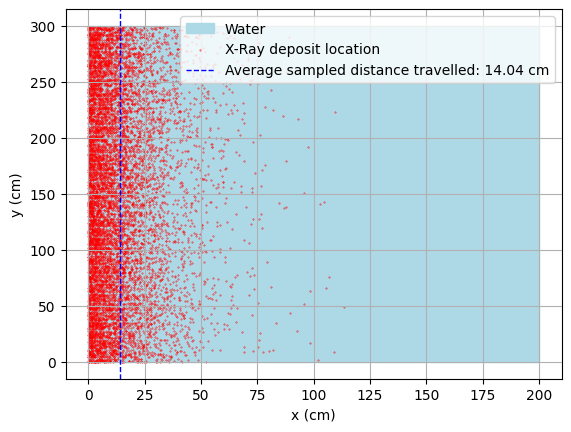

In [227]:
fig, ax = plt.subplots()


start_x = water_rect['start_x']
start_y = water_rect['start_y']
length = water_rect['length']
height = water_rect['height']
label_legend = water_rect['label']
color = water_rect['color']
fill_bool = water_rect['fill']

ax.add_patch(Rectangle((start_x, start_y), length, height, label = label_legend, fill = fill_bool, color=color))
ax.scatter(s,y, s=0.1, color = "red", label = "X-Ray deposit location")
ax.axvline(average_sampled, color='blue', linestyle='--', linewidth=1, label=f'Average sampled distance travelled: {np.mean(s):0.2f} cm')

ax.grid(True)
ax.set_xlabel("x (cm)")
ax.set_ylabel("y (cm)")
plt.legend()
plt.show()

### Adding bone and air

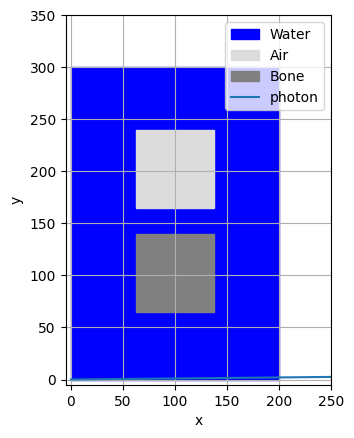

In [136]:
fig, ax = plt.subplots()

for rectangle in rects:
    start_x = rectangle['start_x']
    start_y = rectangle['start_y']
    length = rectangle['length']
    height = rectangle['height']
    label_legend = rectangle['label']
    color = rectangle['color']
    fill_bool = rectangle['fill']
    ax.add_patch(Rectangle((start_x, start_y), length, height, label = label_legend, fill = fill_bool, color=color))


photon1 = np.array([0, 0, 150, 0])
time_array = np.linspace(0,100,1000)
x = 0.1*time_array
plt.plot(x, label = "photon")


ax.set_aspect("equal")
ax.set_xlim(-5, 250)
ax.set_ylim(-5, 350)
ax.grid(True)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.legend()
plt.show()

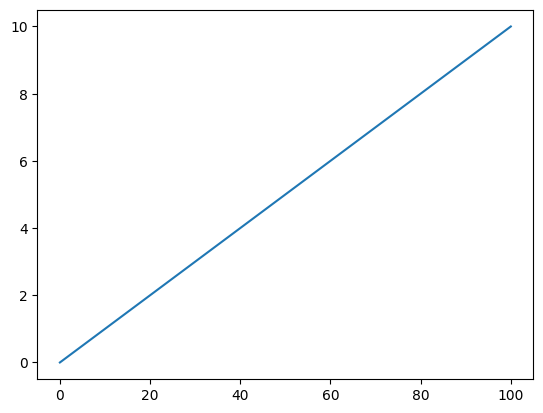

In [131]:
# Particle format is [particlenum, x, y, energy, angle]
photon1 = np.array([0, 0, 150, 0])
time_array = np.linspace(0,100,1000)
x = 0.1*time_array
plt.plot(time_array, x)